# Spectral Clustering: Graph Cuts on Digit Images

**Family:** Unsupervised learning | **Level:** Advanced | **Dataset:** `digits` | **Runs on:** CPU, about 1 minute(s)

Cluster with the eigenvectors of a neighbour graph.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How a similarity graph defines clusters
- What the graph Laplacian eigenvectors do
- How the eigengap suggests k
- Why spectral methods need a good graph

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Digits of the same class lie on curved structures, not round balls.

**The problem.** Cluster digit images with a nearest neighbour graph.

**Why it matters.** Graph methods find non convex groups.

**Why machine learning.** Similarity is local, so a global centre model fails.

**Why this algorithm.** Spectral clustering turns local similarity into global groups.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### A tutorial on spectral clustering

- **Type:** foundational paper
- **Authors:** von Luxburg, U.
- **Year and venue:** 2007, Statistics and Computing 17(4):395-416
- **DOI or URL:** https://doi.org/10.1007/s11222-007-9033-z
- **Verification:** Crossref 2026-11-17
- **Research objective:** Explain spectral clustering from graph Laplacians.
- **Methodology:** Embed points with Laplacian eigenvectors and run k-means.
- **Dataset:** Tutorial examples.
- **Main findings:** Clarifies the link to graph cuts and gives practical advice.
- **Limitations:** Eigen decomposition is costly on large graphs.

**Relationship to this notebook.** von Luxburg's tutorial explains the algorithm and its variants. We implement the normalised symmetric version. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Graph.** Affinity matrix $W$ from k nearest neighbours.

**Normalised Laplacian.** $L_{sym} = I - D^{-1/2} W D^{-1/2}$ with degree matrix $D$.

**Algorithm.** Take the $k$ eigenvectors of $L_{sym}$ with smallest eigenvalues, normalise rows to unit length, and run k-means on the rows.

**Eigengap.** A large jump between consecutive eigenvalues suggests the number of clusters.

**Limits.** Needs a good graph, $O(n^3)$ eigen decomposition for dense solvers, no out of sample prediction.

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "spectral_clustering"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("digits")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (1797, 64)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (1797, 64)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


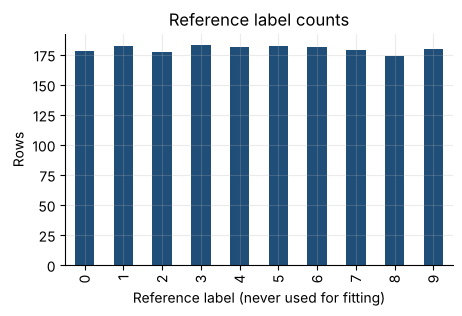

Mean absolute correlation between features: nan


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

We project to 20 principal components and build a 15 nearest neighbour graph. No labels are used.

In [3]:
X = PCA(20, random_state=SEED).fit_transform(X_raw.values)
print(X.shape)

(1797, 20)


## 8. Algorithm Implementation

### 8.1 Concept

Points connected through chains of neighbours end up close in the eigenvector space, where a simple k-means can split them.

### 8.2 Python implementation from scratch

We build the normalised Laplacian from a kNN graph, take eigenvectors and run k-means.

In [4]:
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans, SpectralClustering
W = kneighbors_graph(X, 15, include_self=False)
W = 0.5 * (W + W.T)
W = W.toarray()
deg = W.sum(axis=1)
Dm = np.diag(1 / np.sqrt(deg))
L = np.eye(len(W)) - Dm @ W @ Dm
vals, vecs = np.linalg.eigh(L)
print("smallest 12 eigenvalues:", np.round(vals[:12], 4))
def spectral_scratch(k):
    U = vecs[:, :k]
    U = U / np.linalg.norm(U, axis=1, keepdims=True)
    return KMeans(k, n_init=10, random_state=SEED).fit_predict(U)
mine = spectral_scratch(10)
ref = SpectralClustering(10, affinity="nearest_neighbors", n_neighbors=15, random_state=SEED).fit_predict(X)
print("ARI scratch vs reference digits:", round(external_scores(y_true, mine)["ARI"], 3), "| sklearn:", round(external_scores(y_true, ref)["ARI"], 3))

smallest 12 eigenvalues: [0.     0.0033 0.007  0.0095 0.0124 0.0152 0.017  0.0226 0.025  0.0381
 0.0431 0.0597]
ARI scratch vs reference digits: 0.808 | sklearn: 0.756


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_clusters` | Groups. |
| `affinity` | `nearest_neighbors` or `rbf`. |
| `n_neighbors` | Graph size parameter. |
| `assign_labels` | `kmeans` or `discretize`. |

## 9. Model Training

We choose k from the eigengap and check the choice with silhouette. The reference digit label is not used for selection.

In [5]:
gaps = np.diff(vals[:20])
K_GAP = int(np.argmax(gaps[1:]) + 2)
print("largest eigengap suggests k =", K_GAP)
rows = []
for k in [5, 8, 10, 12, 15]:
    lab = spectral_scratch(k)
    rows.append({"k": k, "silhouette": internal_scores(X, lab)["Silhouette"], "eigengap": float(vals[k] - vals[k - 1])})
sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round(4))
BEST_K = int(sweep["silhouette"].idxmax())
model = SpectralClustering(BEST_K, affinity="nearest_neighbors", n_neighbors=15, random_state=SEED)
labels = model.fit_predict(X)
print("chosen k:", BEST_K)

largest eigengap suggests k = 19


,silhouette,eigengap
k,,
5,0.1244,0.0028
8,0.1955,0.0024
10,0.2030,0.0050
12,0.2059,0.0115
15,0.2140,0.0111


chosen k: 15


## 10. Evaluation

Internal scores need no labels: silhouette (higher is better, range -1 to 1), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). External scores (ARI and NMI) compare with a reference label that was never used for fitting. A reference label is not the truth about the data. It is one possible grouping.

In [6]:
METRICS = {**internal_scores(X, labels), **external_scores(y_true, labels)}
CONFIG = {"k": BEST_K, "n_neighbors": 15, "pca_components": 20}
EXTRA = {"eigengap_k": K_GAP, "sweep": sweep.round(4).reset_index().to_dict("records")}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="SpectralClustering", dataset="digits",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: experiments/results/spectral_clustering.json


,metric
clusters,15.0000
noise_fraction,0.0000
Silhouette,0.2124
Davies_Bouldin,1.6039
Calinski_Harabasz,170.0406
ARI,0.7938
NMI,0.8691


## 11. Visualization

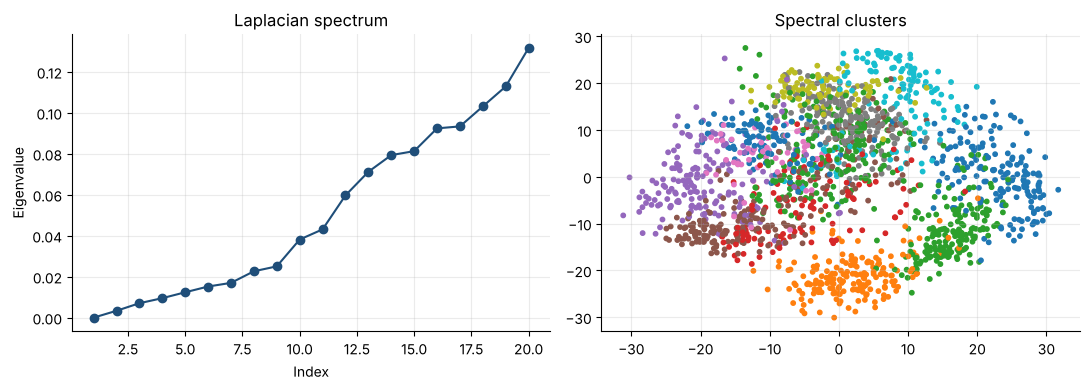

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, 21), vals[:20], marker="o"); axes[0].set_xlabel("Index"); axes[0].set_ylabel("Eigenvalue"); axes[0].set_title("Laplacian spectrum")
Z = PCA(2, random_state=SEED).fit_transform(X)
axes[1].scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=10); axes[1].set_title("Spectral clusters")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

The crosstab shows which digits share a cluster.

In [8]:
display(pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(y_true, name="reference digit")))

reference digit,0,1,2,3,4,5,6,7,8,9
cluster,,,,,,,,,,
0,0,0,0,0,178,0,0,0,0,0
1,0,0,107,0,0,0,0,0,0,0
2,178,0,0,0,0,0,0,0,0,0
3,0,1,13,11,3,0,1,0,166,2
4,0,0,0,0,0,0,180,0,0,0
5,0,0,0,1,0,113,0,0,0,0
6,0,0,0,169,0,0,0,0,1,2
7,0,0,0,1,0,2,0,0,0,143
8,0,57,0,0,0,0,0,0,3,19


## 13. Experiments and Challenges

### Experiment 1: Neighbours in the graph

Too few neighbours disconnect the graph, too many blur it.

In [9]:
for nn in [5, 15, 30, 60]:
    lab = SpectralClustering(BEST_K, affinity="nearest_neighbors", n_neighbors=nn, random_state=SEED).fit_predict(X)
    print(f"n_neighbors={nn}: ARI {external_scores(y_true, lab)['ARI']:.3f}, silhouette {internal_scores(X, lab)['Silhouette']:.3f}")

n_neighbors=5: ARI 0.807, silhouette 0.193
n_neighbors=15: ARI 0.794, silhouette 0.212


n_neighbors=30: ARI 0.775, silhouette 0.211


n_neighbors=60: ARI 0.717, silhouette 0.211


### Experiment 2: Spectral versus k-means

Same k, same input.

In [10]:
km = KMeans(BEST_K, n_init=10, random_state=SEED).fit_predict(X)
print("ARI k-means:", round(external_scores(y_true, km)["ARI"], 3), "| ARI spectral:", round(METRICS["ARI"], 3))

ARI k-means: 0.696 | ARI spectral: 0.794


### Experiment 3: RBF affinity

A dense Gaussian kernel affinity instead of a kNN graph.

In [11]:
for gamma in [0.001, 0.005, 0.02]:
    lab = SpectralClustering(BEST_K, affinity="rbf", gamma=gamma, random_state=SEED).fit_predict(X)
    print(f"gamma={gamma}: ARI {external_scores(y_true, lab)['ARI']:.3f}")

gamma=0.001: ARI 0.609


gamma=0.005: ARI 0.648


gamma=0.02: ARI 0.845


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

von Luxburg stresses that the quality depends on the graph. The neighbour experiment shows this on digit data.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use self tuning affinities and Nystrom approximation for large data.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- The graph decides the result.
- Eigengap guides k.
- No prediction for new rows.

**Use cases.** Image segmentation, community detection.

**Limitations.** Cubic cost, graph sensitivity.

**Recommended next notebook.** PCA.

**Further reading.** See `references.md` in this folder.